# AR(p) Process and Interactive Sliding-Window Complexes

This notebook simulates an autoregressive process, forms forward sliding-window embeddings, estimates completion matrices from the training segment, constructs a sequence of simplicial complexes for `k = 1, ..., k_max`, and plots a selected simple functional as a function of `k`.

The interactive panel below lets you choose:

1. the AR order `p`,
2. the innovation distribution,
3. `k_max`,
4. the simplicial construction rule, and
5. the simple functional profile to plot.

The AR(p) model is

$$x_t = c + \phi_1 x_{t-1} + \cdots + \phi_p x_{t-p} + \varepsilon_t,$$

and the forward embedding of dimension `k` is

$$\mathbf{x}_t^{(k)} = (x_t, x_{t+1}, \ldots, x_{t+k-1}).$$


In [37]:
# If needed, uncomment and run once:
# %pip install ipywidgets gudhi scipy

import ast
import numpy as np
import matplotlib.pyplot as plt
import gudhi
import ipywidgets as widgets

from IPython.display import display, clear_output

plt.style.use("seaborn-v0_8-whitegrid")

# Import every simplex-tree functional from the canonical module.
from pathlib import Path
import importlib.util
import sys

_functional_candidates = [
    Path.cwd() / "001_SIMPLICIAL_COMPLEX_FUNCTIONALS.py",
    Path.cwd() / "Code" / "001_SIMPLICIAL_COMPLEX_FUNCTIONALS.py",
]
FUNCTIONALS_PATH = next((path for path in _functional_candidates if path.exists()), None)
if FUNCTIONALS_PATH is None:
    raise FileNotFoundError("Could not find 001_SIMPLICIAL_COMPLEX_FUNCTIONALS.py")

_functionals_spec = importlib.util.spec_from_file_location(
    "simplicial_complex_functionals", FUNCTIONALS_PATH
)
simplicial_functionals = importlib.util.module_from_spec(_functionals_spec)
sys.modules[_functionals_spec.name] = simplicial_functionals
_functionals_spec.loader.exec_module(simplicial_functionals)

functional_value = simplicial_functionals.functional_value
component_count = simplicial_functionals.beta_0
first_betti_number = simplicial_functionals.beta_1


## Functions

In [38]:
def companion_matrix(phi):
    """Companion matrix for an AR(p) coefficient vector."""
    phi = np.asarray(phi, dtype=float)
    p = phi.size
    matrix = np.zeros((p, p))
    matrix[0, :] = phi
    if p > 1:
        matrix[1:, :-1] = np.eye(p - 1)
    return matrix


def is_stationary(phi):
    """Return whether all companion-matrix eigenvalues lie inside the unit disk."""
    eigenvalues = np.linalg.eigvals(companion_matrix(phi))
    return bool(np.all(np.abs(eigenvalues) < 1)), eigenvalues


def partial_autocorrelations_to_ar(partial_autocorrelations):
    """Convert partial autocorrelations to stationary AR coefficients."""
    coefficients = np.array([], dtype=float)
    for partial in np.asarray(partial_autocorrelations, dtype=float):
        previous = coefficients.copy()
        coefficients = np.empty(previous.size + 1, dtype=float)
        if previous.size:
            coefficients[:-1] = previous - partial * previous[::-1]
        coefficients[-1] = partial
    return coefficients


def random_stationary_ar_coefficients(order, seed=None, pacf_bound=0.8):
    """Generate reproducible stationary AR coefficients of the requested order.

    The random draw is made in partial-autocorrelation coordinates. Any vector
    with entries in (-1, 1) maps to a causal stationary AR polynomial, so this
    avoids repeated rejection sampling. The bound keeps simulated paths from
    being too close to the stationarity boundary by default.
    """
    if not isinstance(order, (int, np.integer)) or order < 1:
        raise ValueError("order must be a positive integer.")
    if not 0 < pacf_bound < 1:
        raise ValueError("pacf_bound must lie strictly between 0 and 1.")

    rng = np.random.default_rng(seed)
    partial_autocorrelations = rng.uniform(-pacf_bound, pacf_bound, size=order)
    phi = partial_autocorrelations_to_ar(partial_autocorrelations)
    stationary, eigenvalues = is_stationary(phi)
    if not stationary:
        raise RuntimeError(
            "Generated coefficients should be stationary, but were not. "
            f"Eigenvalue magnitudes: {np.round(np.abs(eigenvalues), 4)}"
        )
    return phi


def parse_phi(text):
    """Parse entries such as '0.7', '0.6, -0.2', or '[0.6, -0.2]'."""
    text = str(text).strip()
    if not text:
        raise ValueError("Please enter at least one AR coefficient.")
    if text.startswith("[") or text.startswith("("):
        values = ast.literal_eval(text)
    else:
        values = [float(part.strip()) for part in text.split(",")]
    phi = np.atleast_1d(np.asarray(values, dtype=float))
    if phi.ndim != 1 or phi.size == 0 or not np.all(np.isfinite(phi)):
        raise ValueError("AR coefficients must be a finite one-dimensional sequence.")
    return phi



def sample_innovations(rng, distribution, sigma, size, innovation_df=5.0,
                       pareto_shape=2.5):
    """Draw centered innovations. For Cauchy, sigma is the Cauchy scale."""
    if sigma <= 0:
        raise ValueError("sigma / scale must be positive.")

    key = distribution.lower().replace(" ", "-")
    if key == "gaussian":
        return rng.normal(0.0, sigma, size)
    if key == "uniform":
        half_width = np.sqrt(3.0) * sigma
        return rng.uniform(-half_width, half_width, size)
    if key == "laplace":
        return rng.laplace(0.0, sigma / np.sqrt(2.0), size)
    if key in {"student-t", "student"}:
        if innovation_df <= 2:
            raise ValueError("Student-t degrees of freedom must exceed 2 for finite SD.")
        scale = sigma * np.sqrt((innovation_df - 2.0) / innovation_df)
        return scale * rng.standard_t(innovation_df, size)
    if key == "cauchy":
        return sigma * rng.standard_cauchy(size)
    if key in {"centered-pareto", "pareto"}:
        if pareto_shape <= 1:
            raise ValueError("Pareto shape must exceed 1 to center the innovations.")
        raw = sigma * (1.0 + rng.pareto(pareto_shape, size))
        return raw - sigma * pareto_shape / (pareto_shape - 1.0)

    raise ValueError(
        "distribution must be Gaussian, Uniform, Laplace, Student-t, Cauchy, "
        "or Centered Pareto."
    )


def generate_ar_process(phi, n=1_000, sigma=1.0, intercept=0.0,
                        burn_in=500, initial_values=None, seed=None,
                        innovation_distribution="Gaussian", innovation_df=5.0,
                        pareto_shape=2.5):
    """Generate an AR(p) process with selectable innovation distribution."""
    phi = np.asarray(phi, dtype=float)
    if phi.ndim != 1 or phi.size == 0:
        raise ValueError("phi must be a non-empty one-dimensional sequence.")
    if n <= 0 or burn_in < 0:
        raise ValueError("n must be positive and burn_in must be non-negative.")

    p = phi.size
    total = n + burn_in
    x = np.zeros(total + p)

    if initial_values is not None:
        initial_values = np.asarray(initial_values, dtype=float)
        if initial_values.shape != (p,):
            raise ValueError(f"initial_values must contain exactly {p} values.")
        x[:p] = initial_values
    elif abs(1.0 - np.sum(phi)) > 1e-12:
        x[:p] = intercept / (1.0 - np.sum(phi))

    rng = np.random.default_rng(seed)
    innovations = sample_innovations(
        rng,
        innovation_distribution,
        sigma,
        total,
        innovation_df=innovation_df,
        pareto_shape=pareto_shape,
    )

    for t in range(p, total + p):
        past = x[t - p:t][::-1]
        x[t] = intercept + phi @ past + innovations[t - p]

    return x[p + burn_in:p + burn_in + n]


def forward_sliding_window_embedding(x, k):
    """Return rows (x_t, x_(t+1), ..., x_(t+k-1))."""
    x = np.asarray(x, dtype=float)
    if x.ndim != 1:
        raise ValueError("x must be one-dimensional.")
    if not isinstance(k, (int, np.integer)) or not 1 <= k <= x.size:
        raise ValueError("k must be an integer between 1 and len(x).")
    return np.lib.stride_tricks.sliding_window_view(x, window_shape=k).copy()


def fit_completion_matrices(x_train, k_max):
    """Estimate A_hat[k] from complete k_max-windows in the training data."""
    full_windows = forward_sliding_window_embedding(x_train, k_max)
    A_hat = {}

    for k in range(1, k_max + 1):
        Y_k = full_windows[:, :k]
        Z_k = full_windows[:, k:]

        if k == k_max:
            A_hat[k] = np.empty((0, k_max))
        else:
            coefficients, *_ = np.linalg.lstsq(Y_k, Z_k, rcond=None)
            A_hat[k] = coefficients.T

    return A_hat


def lift_windows(x, k, k_max, A_k):
    """Lift k-dimensional forward windows to R^k_max using a fitted A_k."""
    if not 1 <= k <= k_max:
        raise ValueError("k must lie between 1 and k_max.")
    if len(x) < k_max:
        raise ValueError("x must contain at least k_max observations.")

    Y_k = forward_sliding_window_embedding(x, k)[:len(x) - k_max + 1]
    predicted_tail = Y_k @ A_k.T
    return np.hstack((Y_k, predicted_tail))


def prediction_error_vectors(x, k, k_max, A_k):
    """Return z_hat_t^(k) - z_t^(k) for complete k_max-windows."""
    full_windows = forward_sliding_window_embedding(x, k_max)
    if k == k_max:
        return np.zeros((len(full_windows), 0))

    Y_k = full_windows[:, :k]
    true_tail = full_windows[:, k:]
    predicted_tail = Y_k @ A_k.T
    return predicted_tail - true_tail


def innovation_variance(distribution, sigma, innovation_df=5.0, pareto_shape=2.5):
    """Innovation variance used by the theoretical autocovariance rules."""
    key = distribution.lower().replace(" ", "-")
    if key in {"gaussian", "uniform", "laplace"}:
        return float(sigma ** 2)
    if key in {"student-t", "student"}:
        if innovation_df <= 2:
            return np.inf
        return float(sigma ** 2)
    if key == "cauchy":
        return np.inf
    if key in {"centered-pareto", "pareto"}:
        if pareto_shape <= 2:
            return np.inf
        return float(sigma ** 2 * pareto_shape / ((pareto_shape - 1.0) ** 2 * (pareto_shape - 2.0)))
    raise ValueError(f"Unknown innovation distribution: {distribution}")


def stationary_autocovariances(phi, innovation_var, max_lag):
    """Return gamma(0),...,gamma(max_lag) from the AR companion covariance."""
    if not np.isfinite(innovation_var) or innovation_var <= 0:
        raise ValueError("The covariance rules require finite positive innovation variance.")
    matrix = companion_matrix(phi)
    p = matrix.shape[0]
    noise_covariance = np.zeros((p, p))
    noise_covariance[0, 0] = innovation_var
    system = np.eye(p * p) - np.kron(matrix, matrix)
    state_covariance = np.linalg.solve(system, noise_covariance.reshape(-1)).reshape(p, p)

    autocovariances = np.empty(max_lag + 1, dtype=float)
    power = np.eye(p)
    for lag in range(max_lag + 1):
        if lag > 0:
            power = power @ matrix
        autocovariances[lag] = (power @ state_covariance)[0, 0]
    return autocovariances


def covariance_matrix_for_lag(autocovariances, lag, k):
    """C^(k) for two k-windows whose start times differ by lag."""
    indices = np.arange(k)
    offsets = np.abs(-lag + indices[:, None] - indices[None, :])
    return autocovariances[offsets]


def covariance_weights_by_lag(k, k_max, A_k, autocovariances, mode, epsilon=1e-12):
    """Reciprocal covariance-similarity weights indexed by temporal lag."""
    if mode not in {"window", "lifted"}:
        raise ValueError("mode must be 'window' or 'lifted'.")
    lift = np.vstack([np.eye(k), A_k])
    weights = {}
    summaries = {}

    for lag in range(1, k):
        C = covariance_matrix_for_lag(autocovariances, lag, k)
        if mode == "window":
            summary = float(np.sum(C ** 2))
        else:
            D = lift @ C @ lift.T
            summary = float(np.sum(D ** 2))
        summaries[lag] = summary
        weights[lag] = 1.0 / (summary + epsilon)

    return weights, summaries


def _candidate_temporal_edges(n_vertices, k):
    """Candidate edges with 1 <= |s-t| <= k-1."""
    for lag in range(1, k):
        for s in range(n_vertices - lag):
            yield s, s + lag


def _finalize_flag_complex(simplex_tree, k):
    """Expand and initialize persistence; scalar invariants live in the shared module."""
    if k >= 3:
        simplex_tree.expansion(max_dimension=2)
    simplex_tree.compute_persistence(
        homology_coeff_field=2,
        persistence_dim_max=True,
    )
    return simplex_tree


def similar_error_complex(errors, k, tau):
    """Construct L_k as a flag complex using the similar-error rule."""
    errors = np.asarray(errors, dtype=float)
    n_vertices = len(errors)
    simplex_tree = gudhi.SimplexTree()

    for vertex in range(n_vertices):
        simplex_tree.insert([vertex], filtration=0.0)

    error_norms = np.linalg.norm(errors, axis=1)
    retained_edges = []

    for s, t in _candidate_temporal_edges(n_vertices, k):
        difference_norm = np.linalg.norm(errors[s] - errors[t])
        if (error_norms[s] <= tau and
                error_norms[t] <= tau and
                difference_norm <= tau):
            simplex_tree.insert([s, t], filtration=0.0)
            retained_edges.append((s, t))

    _finalize_flag_complex(simplex_tree, k)
    beta_0 = component_count(simplex_tree)
    beta_1 = first_betti_number(simplex_tree)
    return simplex_tree, retained_edges, beta_0, beta_1


def construct_simplicial_complex(errors, lifted_cloud, k, rule,
                                 error_threshold=1.0, distance_threshold=1.0,
                                 covariance_threshold=1.0, k_max=None, A_k=None,
                                 autocovariances=None):
    """Build a flag complex according to the selected construction rule."""
    errors = np.asarray(errors, dtype=float)
    lifted_cloud = np.asarray(lifted_cloud, dtype=float)
    n_vertices = len(errors)
    simplex_tree = gudhi.SimplexTree()

    for vertex in range(n_vertices):
        simplex_tree.insert([vertex], filtration=0.0)

    candidates = list(_candidate_temporal_edges(n_vertices, k))
    error_norms = np.linalg.norm(errors, axis=1)
    retained_edges = []

    if rule == "Both errors small":
        threshold_label = f"||e_s||, ||e_t|| <= {error_threshold:.4g}"
        for s, t in candidates:
            if error_norms[s] <= error_threshold and error_norms[t] <= error_threshold:
                simplex_tree.insert([s, t], filtration=0.0)
                retained_edges.append((s, t))

    elif rule == "Similar errors":
        threshold_label = f"||e_s - e_t|| <= {error_threshold:.4g}"
        for s, t in candidates:
            if np.linalg.norm(errors[s] - errors[t]) <= error_threshold:
                simplex_tree.insert([s, t], filtration=0.0)
                retained_edges.append((s, t))

    elif rule == "Lifted-cloud distance graph":
        threshold_label = f"||p_s - p_t|| <= {distance_threshold:.4g}"
        for s, t in candidates:
            distance = np.linalg.norm(lifted_cloud[s] - lifted_cloud[t])
            if distance <= distance_threshold:
                simplex_tree.insert([s, t], filtration=0.0)
                retained_edges.append((s, t))

    elif rule == "Window covariance similarity":
        if k_max is None or A_k is None or autocovariances is None:
            raise ValueError("The covariance rules require k_max, A_k, and autocovariances.")
        weights_by_lag, _ = covariance_weights_by_lag(
            k, k_max, A_k, autocovariances, mode="window"
        )
        threshold_label = f"1/(rho+eps) <= {covariance_threshold:.4g}"
        for s, t in candidates:
            if weights_by_lag[t - s] <= covariance_threshold:
                simplex_tree.insert([s, t], filtration=0.0)
                retained_edges.append((s, t))

    elif rule == "Lifted covariance similarity":
        if k_max is None or A_k is None or autocovariances is None:
            raise ValueError("The covariance rules require k_max, A_k, and autocovariances.")
        weights_by_lag, _ = covariance_weights_by_lag(
            k, k_max, A_k, autocovariances, mode="lifted"
        )
        threshold_label = f"1/(eta+eps) <= {covariance_threshold:.4g}"
        for s, t in candidates:
            if weights_by_lag[t - s] <= covariance_threshold:
                simplex_tree.insert([s, t], filtration=0.0)
                retained_edges.append((s, t))

    elif rule == "Full temporal graph":
        for s, t in candidates:
            simplex_tree.insert([s, t], filtration=0.0)
            retained_edges.append((s, t))
        threshold_label = "all temporal candidate edges"

    else:
        raise ValueError(f"Unknown simplicial construction rule: {rule}")

    _finalize_flag_complex(simplex_tree, k)
    beta_0 = component_count(simplex_tree)
    beta_1 = first_betti_number(simplex_tree)
    return simplex_tree, retained_edges, beta_0, beta_1, threshold_label


def simplices_by_dimension(simplex_tree, max_dimension=2):
    """Return the simplices of a GUDHI complex grouped by dimension."""
    grouped = {dimension: [] for dimension in range(max_dimension + 1)}
    for simplex, _ in simplex_tree.get_filtration():
        dimension = len(simplex) - 1
        if dimension <= max_dimension:
            grouped[dimension].append(tuple(sorted(simplex)))
    return grouped


def candidate_edge_count(n_vertices, k):
    """Number of temporal candidate edges with 1 <= |s-t| <= k-1."""
    return sum(n_vertices - lag for lag in range(1, k))






def simplex_set(simplex_tree, max_dimension=2):
    """Return the simplices of a complex as sorted tuples."""
    simplices = set()
    for simplex, _ in simplex_tree.get_filtration():
        if len(simplex) - 1 <= max_dimension:
            simplices.add(tuple(sorted(simplex)))
    return simplices




def simplex_tree_from_simplices(simplices):
    """Build a SimplexTree from an iterable of simplices."""
    simplex_tree = gudhi.SimplexTree()
    for simplex in sorted(simplices, key=lambda s: (len(s), s)):
        simplex_tree.insert(list(simplex), filtration=0.0)
    return simplex_tree


def combine_complexes(simplex_tree_a, simplex_tree_b, operation):
    """Return K union L or K intersection L as a new SimplexTree."""
    simplices_a = simplex_set(simplex_tree_a, max_dimension=2)
    simplices_b = simplex_set(simplex_tree_b, max_dimension=2)

    if operation == "union":
        combined = simplices_a | simplices_b
    elif operation == "intersection":
        combined = simplices_a & simplices_b
    else:
        raise ValueError("operation must be 'union' or 'intersection'.")

    return simplex_tree_from_simplices(combined)


def scale_similarity_matrix(
    complexes_by_k,
    k_values,
    functional_1_name,
    functional_2_name,
    functional_1_weight,
    functional_2_weight,
    operation,
):
    """Matrix S_kl = a F1(L_k op L_l) + b F2(L_k op L_l)."""
    n_scales = len(k_values)
    matrix = np.zeros((n_scales, n_scales), dtype=float)

    for row, k in enumerate(k_values):
        for column in range(row, n_scales):
            ell = k_values[column]
            combined = combine_complexes(complexes_by_k[k], complexes_by_k[ell], operation)
            value_1 = functional_value(combined, functional_1_name)
            value_2 = functional_value(combined, functional_2_name)
            value = functional_1_weight * value_1 + functional_2_weight * value_2
            matrix[row, column] = value
            matrix[column, row] = value

    return matrix


def principal_eigenvector(matrix):
    """Principal eigenvector of a symmetric scale-similarity matrix."""
    matrix = np.asarray(matrix, dtype=float)
    if matrix.size == 0 or np.allclose(matrix, 0):
        return np.zeros(matrix.shape[0], dtype=float), 0.0

    eigenvalues, eigenvectors = np.linalg.eigh((matrix + matrix.T) / 2.0)
    index = int(np.argmax(eigenvalues))
    vector = np.real(eigenvectors[:, index])
    if vector.sum() < 0:
        vector = -vector
    return vector, float(eigenvalues[index])


FUNCTIONAL_OPTIONS = [
    "f0 (vertices)",
    "f1 (edges)",
    "f2 (triangles)",
    "beta0",
    "beta1",
    "point complexity",
]

## Interactive pipeline

Choose the AR order `p`, innovation distribution, `k_max`, the construction rule for the complexes, and the simple functional to plot. Press **Run pipeline** to regenerate everything. The AR coefficients are drawn randomly from the seed using stationary partial-autocorrelation coordinates, so the same `p` and seed reproduce the same coefficients. The latest run is also stored in the global variables `x`, `x_train`, `x_test`, `phi`, `A_hat`, `lifted_test_clouds`, `complexes_L`, `retained_edges_by_k`, `betti_by_k`, `thesis_functionals`, and `interactive_pipeline_result`.


In [39]:
def run_sliding_window_pipeline(order_p=2, n=1_000, sigma=0.7,
                                intercept=0.0, burn_in=500, seed=42,
                                train_fraction=0.7, k_max=5,
                                innovation_distribution="Gaussian",
                                innovation_df=5.0, pareto_shape=2.5,
                                construction_rule="Both errors small",
                                error_threshold=1.0,
                                distance_threshold=1.0,
                                covariance_threshold=1.0,
                                functional_1_name="beta0",
                                functional_2_name="f1 (edges)",
                                functional_1_weight=1.0,
                                functional_2_weight=1.0,
                                similarity_operation="union"):
    """Run the simulation, complex construction, linear profile, and similarity plot."""
    global phi, x, x_train, x_test, A_hat, lifted_test_clouds
    global test_error_vectors, complexes_L, retained_edges_by_k, betti_by_k
    global threshold_by_k, k_values, thesis_functionals, interactive_pipeline_result
    global scale_similarity, scale_similarity_principal_eigenvector

    phi = random_stationary_ar_coefficients(order_p, seed=seed)
    stationary, eigenvalues = is_stationary(phi)
    if not stationary:
        raise ValueError(
            "The selected AR coefficients are not stationary. "
            f"Companion eigenvalue magnitudes: {np.round(np.abs(eigenvalues), 4)}"
        )
    if not 0 < train_fraction < 1:
        raise ValueError("train_fraction must lie between 0 and 1.")
    if not 1 <= k_max <= int(train_fraction * n):
        raise ValueError("k_max must be positive and small enough for the training part.")
    if not 1 <= k_max <= n - int(train_fraction * n):
        raise ValueError("k_max must be small enough for the test part.")
    if error_threshold < 0:
        raise ValueError("error_threshold must be non-negative.")
    if distance_threshold < 0:
        raise ValueError("distance_threshold must be non-negative.")
    if covariance_threshold < 0:
        raise ValueError("covariance_threshold must be non-negative.")

    x = generate_ar_process(
        phi=phi,
        n=n,
        sigma=sigma,
        intercept=intercept,
        burn_in=burn_in,
        seed=seed,
        innovation_distribution=innovation_distribution,
        innovation_df=innovation_df,
        pareto_shape=pareto_shape,
    )

    split_index = int(train_fraction * len(x))
    x_train = x[:split_index]
    x_test = x[split_index:]
    A_hat = fit_completion_matrices(x_train, k_max=k_max)
    k_values = np.arange(1, k_max + 1)
    covariance_rule_names = {"Window covariance similarity", "Lifted covariance similarity"}
    autocovariances = None
    if construction_rule in covariance_rule_names:
        innovation_var = innovation_variance(
            innovation_distribution,
            sigma,
            innovation_df=innovation_df,
            pareto_shape=pareto_shape,
        )
        autocovariances = stationary_autocovariances(
            phi, innovation_var, max_lag=2 * k_max
        )

    lifted_test_clouds = {}
    test_error_vectors = {}
    complexes_L = {}
    retained_edges_by_k = {}
    betti_by_k = {}
    threshold_by_k = {}
    threshold_labels = {}
    candidate_edge_counts = {}

    for k in k_values:
        lifted_test_clouds[k] = lift_windows(x_test, k=k, k_max=k_max, A_k=A_hat[k])
        test_error_vectors[k] = prediction_error_vectors(x_test, k, k_max, A_hat[k])
        L_k, retained_edges, beta_0, beta_1, threshold_label = construct_simplicial_complex(
            errors=test_error_vectors[k],
            lifted_cloud=lifted_test_clouds[k],
            k=k,
            rule=construction_rule,
            error_threshold=error_threshold,
            distance_threshold=distance_threshold,
            covariance_threshold=covariance_threshold,
            k_max=k_max,
            A_k=A_hat[k],
            autocovariances=autocovariances,
        )
        complexes_L[k] = L_k
        retained_edges_by_k[k] = retained_edges
        betti_by_k[k] = (beta_0, beta_1)
        threshold_by_k[k] = {
            "error_threshold": error_threshold,
            "distance_threshold": distance_threshold,
            "covariance_threshold": covariance_threshold,
        }
        threshold_labels[k] = threshold_label
        candidate_edge_counts[k] = candidate_edge_count(len(test_error_vectors[k]), k)

    functional_1_values = np.array([
        functional_value(complexes_L[k], functional_1_name)
        for k in k_values
    ], dtype=float)
    functional_2_values = np.array([
        functional_value(complexes_L[k], functional_2_name)
        for k in k_values
    ], dtype=float)
    functional_values = (
        functional_1_weight * functional_1_values
        + functional_2_weight * functional_2_values
    )
    functional_label = (
        f"{functional_1_weight:g}*{functional_1_name} + "
        f"{functional_2_weight:g}*{functional_2_name}"
    )

    scale_similarity = scale_similarity_matrix(
        complexes_L,
        k_values,
        functional_1_name,
        functional_2_name,
        functional_1_weight,
        functional_2_weight,
        similarity_operation,
    )
    scale_similarity_principal_eigenvector, principal_eigenvalue = principal_eigenvector(
        scale_similarity
    )

    thesis_functionals = {
        functional_1_name: functional_1_values,
        functional_2_name: functional_2_values,
        functional_label: functional_values,
    }
    interactive_pipeline_result = {
        "p": int(order_p),
        "phi": phi,
        "innovation_distribution": innovation_distribution,
        "k_max": k_max,
        "construction_rule": construction_rule,
        "covariance_threshold": covariance_threshold,
        "functional_1_name": functional_1_name,
        "functional_2_name": functional_2_name,
        "functional_1_weight": functional_1_weight,
        "functional_2_weight": functional_2_weight,
        "functional_values": functional_values,
        "functional_1_values": functional_1_values,
        "functional_2_values": functional_2_values,
        "scale_similarity_functional_1": functional_1_name,
        "scale_similarity_functional_2": functional_2_name,
        "scale_similarity_functional_1_weight": functional_1_weight,
        "scale_similarity_functional_2_weight": functional_2_weight,
        "scale_similarity_operation": similarity_operation,
        "scale_similarity": scale_similarity,
        "scale_similarity_principal_eigenvector": scale_similarity_principal_eigenvector,
        "scale_similarity_principal_eigenvalue": principal_eigenvalue,
        "candidate_edge_counts": candidate_edge_counts,
        "threshold_by_k": threshold_by_k,
        "threshold_labels": threshold_labels,
    }

    print(
        f"AR({len(phi)}) with {innovation_distribution} innovations; "
        f"n={len(x)}, train={len(x_train)}, test={len(x_test)}, k_max={k_max}."
    )
    print(f"Simplicial construction rule: {construction_rule}")
    print(f"Functional plotted: {functional_label}")
    print(
        "Scale similarity: S[k,l] = "
        f"{functional_label}(L_k {similarity_operation} L_l)"
    )
    print("Random AR coefficients:", np.round(phi, 4).tolist())
    print(f"Sample mean={x.mean():.3f}, sample SD={x.std(ddof=1):.3f}")

    fig, ax = plt.subplots(figsize=(12, 3.8))
    time = np.arange(len(x))
    ax.plot(time[:split_index], x_train, color="tab:blue", linewidth=0.9,
            label="training part")
    ax.plot(time[split_index:], x_test, color="tab:orange", linewidth=0.9,
            label="test part")
    ax.axvline(split_index - 0.5, color="black", linestyle=":", linewidth=1.1,
               label="train/test split")
    ax.axhline(x.mean(), color="tab:red", linestyle="--", linewidth=1.1,
               label=f"sample mean = {x.mean():.2f}")
    robust_limits = np.quantile(x[np.isfinite(x)], [0.005, 0.995])
    if robust_limits[0] < robust_limits[1]:
        margin = 0.08 * (robust_limits[1] - robust_limits[0])
        ax.set_ylim(robust_limits[0] - margin, robust_limits[1] + margin)
    ax.set(
        title=f"Simulated AR({len(phi)}) process",
        xlabel="time t",
        ylabel="x_t",
    )
    ax.legend(ncol=2)
    fig.tight_layout()
    plt.show()

    plot_xticks = k_values if k_max <= 20 else np.unique(
        np.linspace(1, k_max, 11, dtype=int)
    )

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(k_values, functional_values, marker="o", linewidth=2)
    if len(phi) <= k_max:
        ax.axvline(len(phi), color="tab:red", linestyle="--", linewidth=1.5,
                   label=f"true p={len(phi)}")
        ax.legend()
    ax.set(
        title="Linear Combination of Selected Functionals vs k",
        xlabel="embedding scale k",
        ylabel=functional_label,
        xticks=plot_xticks,
    )
    fig.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(k_values, scale_similarity_principal_eigenvector, marker="o", linewidth=2)
    if len(phi) <= k_max:
        ax.axvline(len(phi), color="tab:red", linestyle="--", linewidth=1.5,
                   label=f"true p={len(phi)}")
        ax.legend()
    ax.set(
        title="Principal Eigenvector of Scale-Similarity Matrix",
        xlabel="embedding scale k",
        ylabel="principal eigenvector entry",
        xticks=plot_xticks,
    )
    fig.tight_layout()
    plt.show()

    max_value = np.nanmax(functional_values)
    maximizing_k = k_values[np.flatnonzero(np.isclose(functional_values, max_value))]
    print(f"Maximizing k values for the linear combination: {maximizing_k.tolist()}")
    print(f"Principal eigenvalue of the scale-similarity matrix: {principal_eigenvalue:.4g}")
    print()
    print(" k | vertices | candidates | retained | beta0 | beta1 | threshold")
    print("---+----------+------------+----------+-------+-------+----------------")
    for k in k_values:
        print(
            f"{k:2d} | {complexes_L[k].num_vertices():8d} | "
            f"{candidate_edge_counts[k]:10d} | {len(retained_edges_by_k[k]):8d} | "
            f"{betti_by_k[k][0]:5d} | {betti_by_k[k][1]:5d} | {threshold_labels[k]}"
        )

    return interactive_pipeline_result


order_p_widget = widgets.BoundedIntText(
    value=2,
    min=1,
    max=20,
    step=1,
    description="AR order p:",
    style={"description_width": "130px"},
    layout=widgets.Layout(width="260px"),
)
innovation_widget = widgets.Dropdown(
    options=["Gaussian", "Uniform", "Laplace", "Student-t", "Cauchy", "Centered Pareto"],
    value="Gaussian",
    description="Innovations:",
    style={"description_width": "130px"},
)
k_max_widget = widgets.BoundedIntText(
    value=5,
    min=1,
    max=50,
    step=1,
    description="k_max:",
    style={"description_width": "130px"},
    layout=widgets.Layout(width="260px"),
)
rule_widget = widgets.Dropdown(
    options=[
        "Both errors small",
        "Similar errors",
        "Lifted-cloud distance graph",
        "Window covariance similarity",
        "Lifted covariance similarity",
        "Full temporal graph",
    ],
    value="Both errors small",
    description="Complex rule:",
    style={"description_width": "130px"},
    layout=widgets.Layout(width="380px"),
)
functional_1_widget = widgets.Dropdown(
    options=FUNCTIONAL_OPTIONS,
    value="beta0",
    description="Functional 1:",
    style={"description_width": "130px"},
    layout=widgets.Layout(width="380px"),
)
functional_2_widget = widgets.Dropdown(
    options=FUNCTIONAL_OPTIONS,
    value="f1 (edges)",
    description="Functional 2:",
    style={"description_width": "130px"},
    layout=widgets.Layout(width="380px"),
)
functional_1_weight_widget = widgets.FloatSlider(
    value=1.0,
    min=-10.0,
    max=10.0,
    step=0.1,
    description="a:",
    style={"description_width": "130px"},
    continuous_update=False,
)
functional_2_weight_widget = widgets.FloatSlider(
    value=1.0,
    min=-10.0,
    max=10.0,
    step=0.1,
    description="b:",
    style={"description_width": "130px"},
    continuous_update=False,
)
similarity_operation_widget = widgets.ToggleButtons(
    options=["union", "intersection"],
    value="union",
    description="oplus:",
    style={"description_width": "130px"},
)
n_widget = widgets.BoundedIntText(
    value=1_000,
    min=100,
    max=200_000,
    step=100,
    description="Sample size:",
    style={"description_width": "130px"},
    layout=widgets.Layout(width="260px"),
)
sigma_widget = widgets.FloatSlider(
    value=0.7,
    min=0.05,
    max=3.0,
    step=0.05,
    description="Scale / SD:",
    style={"description_width": "130px"},
    continuous_update=False,
)
error_threshold_widget = widgets.FloatLogSlider(
    value=1.0,
    base=10,
    min=-3,
    max=3,
    step=0.05,
    description="Error tau:",
    style={"description_width": "130px"},
    continuous_update=False,
)

distance_threshold_widget = widgets.FloatLogSlider(
    value=1.0,
    base=10,
    min=-3,
    max=3,
    step=0.05,
    description="Distance tau:",
    style={"description_width": "130px"},
    continuous_update=False,
)

covariance_threshold_widget = widgets.FloatLogSlider(
    value=1.0,
    base=10,
    min=-6,
    max=6,
    step=0.05,
    description="Covariance tau:",
    style={"description_width": "130px"},
    continuous_update=False,
)

df_widget = widgets.FloatSlider(
    value=5.0,
    min=2.1,
    max=30.0,
    step=0.1,
    description="Student df:",
    style={"description_width": "130px"},
    continuous_update=False,
)
pareto_widget = widgets.FloatSlider(
    value=2.5,
    min=1.1,
    max=10.0,
    step=0.1,
    description="Pareto shape:",
    style={"description_width": "130px"},
    continuous_update=False,
)
seed_widget = widgets.IntText(
    value=42,
    description="Seed:",
    style={"description_width": "130px"},
    layout=widgets.Layout(width="260px"),
)
run_button = widgets.Button(
    description="Run pipeline",
    button_style="primary",
    icon="play",
)
output = widgets.Output()


def _on_run_clicked(_):
    with output:
        clear_output(wait=True)
        try:
            run_sliding_window_pipeline(
                order_p=order_p_widget.value,
                n=n_widget.value,
                sigma=sigma_widget.value,
                seed=seed_widget.value,
                k_max=k_max_widget.value,
                innovation_distribution=innovation_widget.value,
                innovation_df=df_widget.value,
                pareto_shape=pareto_widget.value,
                construction_rule=rule_widget.value,
                error_threshold=error_threshold_widget.value,
                distance_threshold=distance_threshold_widget.value,
                covariance_threshold=covariance_threshold_widget.value,
                functional_1_name=functional_1_widget.value,
                functional_2_name=functional_2_widget.value,
                functional_1_weight=functional_1_weight_widget.value,
                functional_2_weight=functional_2_weight_widget.value,
                similarity_operation=similarity_operation_widget.value,
            )
        except Exception as exc:
            print(f"Could not run pipeline: {exc}")


run_button.on_click(_on_run_clicked)

controls = widgets.VBox([
    widgets.HTML("<b>Interactive AR sliding-window complex pipeline</b>"),
    widgets.HBox([order_p_widget, innovation_widget]),
    widgets.HBox([k_max_widget, n_widget, seed_widget]),
    widgets.HBox([rule_widget]),
    widgets.HBox([functional_1_widget, functional_1_weight_widget]),
    widgets.HBox([functional_2_widget, functional_2_weight_widget]),
    widgets.HBox([similarity_operation_widget]),
    widgets.HBox([sigma_widget, error_threshold_widget, distance_threshold_widget]),
    widgets.HBox([covariance_threshold_widget]),
    widgets.HBox([df_widget, pareto_widget]),
    run_button,
])

display(controls, output)
_on_run_clicked(None)


Output()

## Choose the AR(p) order

Set `order_p` and `coefficient_seed` below. The AR coefficients are generated randomly, but stationarily, from the seed. A burn-in period reduces the influence of the initialization.


In [55]:
# Model and simulation settings
order_p = 2
coefficient_seed = 42
phi = random_stationary_ar_coefficients(order_p, seed=coefficient_seed)
n = 1_000
sigma = 0.7
intercept = 0.0
burn_in = 500
seed = 42
train_fraction = 0.7
k_max = 5

x = generate_ar_process(
    phi=phi,
    n=n,
    sigma=sigma,
    intercept=intercept,
    burn_in=burn_in,
    seed=seed,
)

split_index = int(train_fraction * len(x))
x_train = x[:split_index]
x_test = x[split_index:]

print(f"Generated an AR({len(phi)}) process with {len(x)} observations.")
print("Random AR coefficients:", np.round(phi, 4).tolist())
print(f"Training observations: {len(x_train)}")
print(f"Test observations: {len(x_test)}")
print(f"Sample mean: {x.mean():.3f}")
print(f"Sample standard deviation: {x.std(ddof=1):.3f}")


Generated an AR(2) process with 1000 observations.
Training observations: 700
Test observations: 300
Sample mean: -0.035
Sample standard deviation: 0.954


## Plot the AR(p) process

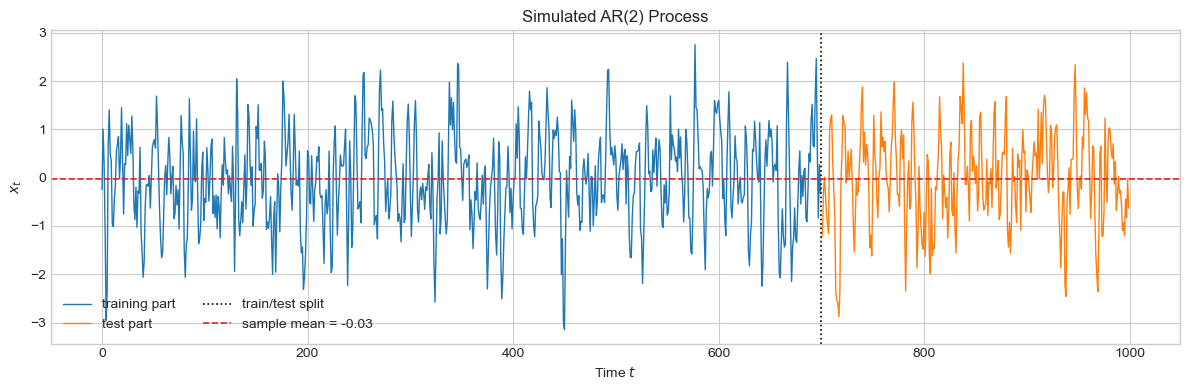

In [56]:
fig, ax = plt.subplots(figsize=(12, 4))
time = np.arange(n)
ax.plot(time[:split_index], x_train, color="tab:blue", linewidth=1.0,
        label="training part")
ax.plot(time[split_index:], x_test, color="tab:orange", linewidth=1.0,
        label="test part")
ax.axvline(split_index - 0.5, color="black", linestyle=":", linewidth=1.2,
           label="train/test split")
ax.axhline(x.mean(), color="tab:red", linestyle="--", linewidth=1.2,
           label=f"sample mean = {x.mean():.2f}")
ax.set(
    title=f"Simulated AR({len(phi)}) Process",
    xlabel="Time $t$",
    ylabel="$x_t$",
)
ax.legend(ncol=2)
fig.tight_layout()
plt.show()

## Forward sliding-window embeddings

Each row of `cloud_k2` is $(x_t, x_{t+1})$, and each row of `cloud_k3` is $(x_t, x_{t+1}, x_{t+2})$.

In [57]:
cloud_k2 = forward_sliding_window_embedding(x, k=2)
cloud_k3 = forward_sliding_window_embedding(x, k=3)

print("k=2 cloud shape:", cloud_k2.shape)
print("k=3 cloud shape:", cloud_k3.shape)

k=2 cloud shape: (999, 2)
k=3 cloud shape: (998, 3)


### Point cloud for k = 2

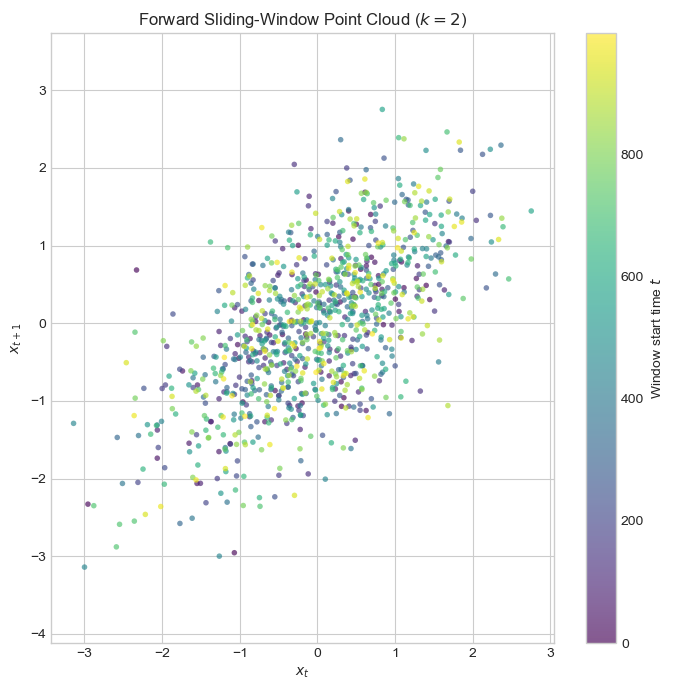

In [58]:
fig, ax = plt.subplots(figsize=(7, 7))
scatter = ax.scatter(
    cloud_k2[:, 0],
    cloud_k2[:, 1],
    c=np.arange(len(cloud_k2)),
    cmap="viridis",
    s=16,
    alpha=0.65,
    edgecolors="none",
)
ax.set(
    title="Forward Sliding-Window Point Cloud ($k=2$)",
    xlabel="$x_t$",
    ylabel="$x_{t+1}$",
)
ax.set_aspect("equal", adjustable="datalim")
fig.colorbar(scatter, ax=ax, label="Window start time $t$")
fig.tight_layout()
plt.show()

### Point cloud for k = 3

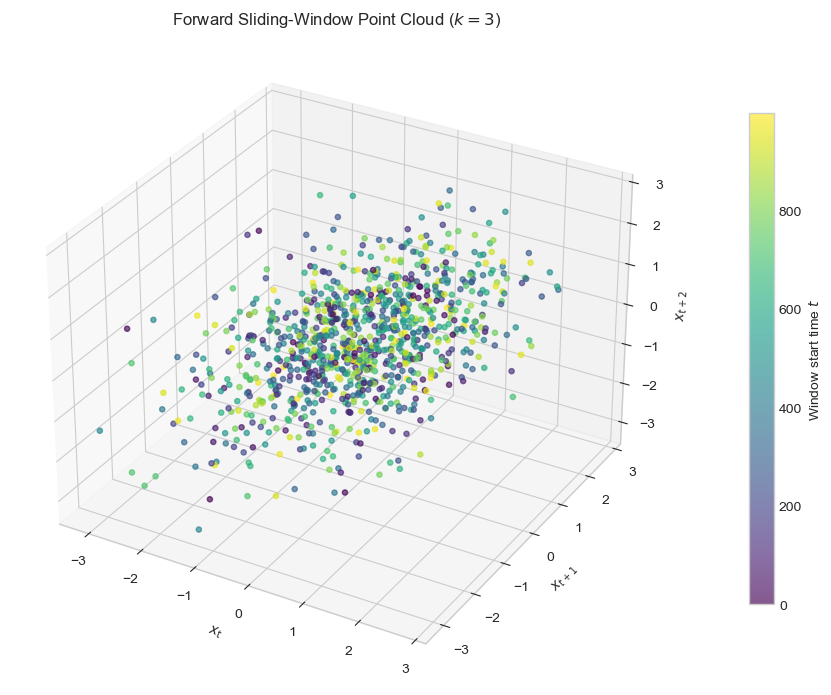

In [59]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
scatter = ax.scatter(
    cloud_k3[:, 0],
    cloud_k3[:, 1],
    cloud_k3[:, 2],
    c=np.arange(len(cloud_k3)),
    cmap="viridis",
    s=14,
    alpha=0.65,
    depthshade=True,
)
ax.set(
    title="Forward Sliding-Window Point Cloud ($k=3$)",
    xlabel="$x_t$",
    ylabel="$x_{t+1}$",
    zlabel="$x_{t+2}$",
)
fig.colorbar(scatter, ax=ax, pad=0.1, shrink=0.75,
             label="Window start time $t$")
fig.tight_layout()
plt.show()

## Train the completion matrices $\hat A_k$

For each $k=1,\ldots,k_{\max}$, every complete training window of length $k_{\max}$ is split into

$$Y_t^{(k)}=(x_t,\ldots,x_{t+k-1})^T$$

and its missing future tail

$$z_t^{(k)}=(x_{t+k},\ldots,x_{t+k_{\max}-1})^T.$$

The matrix $\hat A_k\in\mathbb{R}^{(k_{\max}-k)\times k}$ is estimated only from the training part by minimizing

$$\sum_t\left\|z_t^{(k)}-A Y_t^{(k)}\right\|_2^2.$$

For $k=k_{\max}$, no coordinates are missing, so $\hat A_{k_{\max}}$ is an empty completion matrix.

In [60]:
A_hat = fit_completion_matrices(x_train, k_max=k_max)

for k, A_k in A_hat.items():
    print(f"A_hat[{k}] shape = {A_k.shape}")
    if A_k.size:
        print(np.round(A_k, 3))
    else:
        print("No completion is needed for k = k_max.")
    print()

A_hat[1] shape = (4, 1)
[[ 0.636]
 [ 0.223]
 [ 0.018]
 [-0.046]]

A_hat[2] shape = (3, 2)
[[-0.304  0.829]
 [-0.209  0.356]
 [-0.096  0.078]]

A_hat[3] shape = (2, 3)
[[ 0.047 -0.341  0.841]
 [ 0.015 -0.224  0.365]]

A_hat[4] shape = (1, 4)
[[-0.024  0.061 -0.339  0.838]]

A_hat[5] shape = (0, 5)
No completion is needed for k = k_max.



## Lift the test point clouds to $\mathbb{R}^{k_{\max}}$

The fitted matrices are now frozen. For each $k$, the test windows are lifted according to

$$p_t^{(k)}=\begin{pmatrix}Y_t^{(k)}\\ \hat A_kY_t^{(k)}\end{pmatrix}\in\mathbb{R}^{k_{\max}}.$$

Only windows lying completely within the test segment are used. Every lifted cloud therefore has the same number of points and the same ambient dimension.

In [61]:
lifted_test_clouds = {
    k: lift_windows(x_test, k=k, k_max=k_max, A_k=A_hat[k])
    for k in range(1, k_max + 1)
}

for k, cloud in lifted_test_clouds.items():
    print(f"Lifted test cloud for k={k}: {cloud.shape}")

assert all(cloud.shape[1] == k_max for cloud in lifted_test_clouds.values())
assert len({cloud.shape[0] for cloud in lifted_test_clouds.values()}) == 1

Lifted test cloud for k=1: (296, 5)
Lifted test cloud for k=2: (296, 5)
Lifted test cloud for k=3: (296, 5)
Lifted test cloud for k=4: (296, 5)
Lifted test cloud for k=5: (296, 5)


### Out-of-sample completion error

The following diagnostic compares the predicted coordinates with the actual unseen coordinates in the complete test windows. For $k=k_{\max}$ there is no prediction error because no completion is required.

In [62]:
true_test_windows = forward_sliding_window_embedding(x_test, k_max)
test_rmse = {}

for k in range(1, k_max + 1):
    if k == k_max:
        test_rmse[k] = 0.0
    else:
        predicted_tail = lifted_test_clouds[k][:, k:]
        true_tail = true_test_windows[:, k:]
        test_rmse[k] = np.sqrt(np.mean((true_tail - predicted_tail) ** 2))

for k, rmse in test_rmse.items():
    print(f"k={k}: test completion RMSE = {rmse:.4f}")

k=1: test completion RMSE = 0.9079
k=2: test completion RMSE = 0.8827
k=3: test completion RMSE = 0.8393
k=4: test completion RMSE = 0.7436
k=5: test completion RMSE = 0.0000


### Visualize the lifted test clouds

The lifted clouds live in $\mathbb{R}^5$, which cannot be displayed directly. The plots below show their first three ambient coordinates. The full five-dimensional arrays remain available in `lifted_test_clouds`.

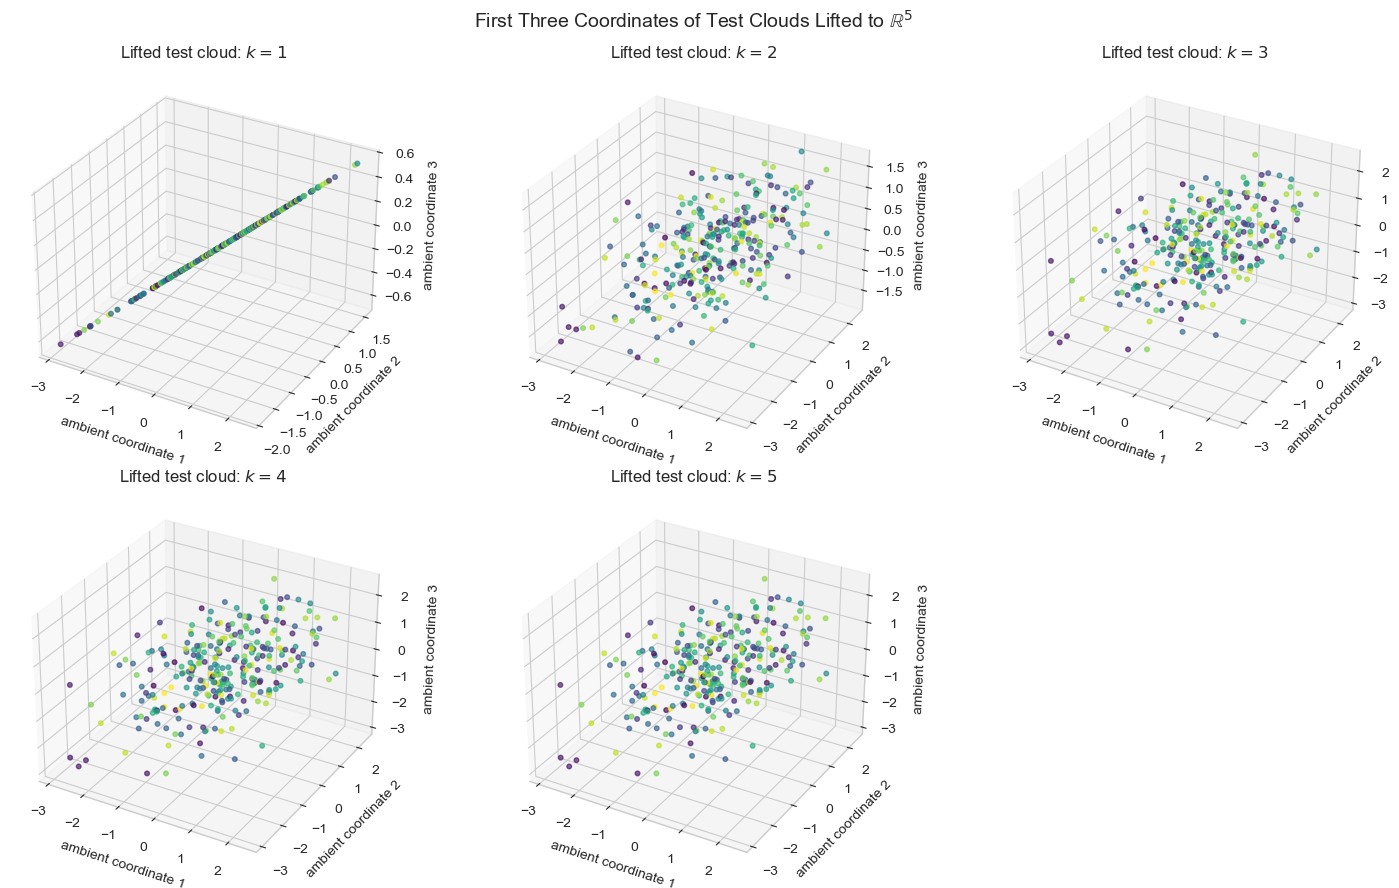

In [63]:
fig = plt.figure(figsize=(15, 9))

for k in range(1, k_max + 1):
    ax = fig.add_subplot(2, 3, k, projection="3d")
    cloud = lifted_test_clouds[k]
    ax.scatter(
        cloud[:, 0], cloud[:, 1], cloud[:, 2],
        c=np.arange(len(cloud)), cmap="viridis",
        s=11, alpha=0.65, depthshade=True,
    )
    ax.set_title(f"Lifted test cloud: $k={k}$")
    ax.set_xlabel("ambient coordinate 1")
    ax.set_ylabel("ambient coordinate 2")
    ax.set_zlabel("ambient coordinate 3")

fig.suptitle(
    f"First Three Coordinates of Test Clouds Lifted to $\\mathbb{{R}}^{k_max}$",
    fontsize=14,
)
fig.tight_layout()
plt.show()